In [9]:
import pandas as pd

In [10]:
import numpy as np

In [11]:
import matplotlib.pyplot as plt

In [12]:
import seaborn as sns

In [13]:
df=pd.read_csv("zomato_data.csv")

In [14]:
df.head()

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [15]:
df.shape

(148, 7)

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Restaurant Name              148 non-null    str  
 1   Online_Order                 148 non-null    str  
 2   Book_Table                   148 non-null    str  
 3   Rate                         148 non-null    str  
 4   Votes                        148 non-null    int64
 5   Approx_Cost(For Two People)  148 non-null    int64
 6   Listed_In(Type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 8.2 KB


In [17]:
df.describe(include="all")

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
count,148,148,148,148,148.000000,148.000000,148
unique,145,2,2,20,NaN,NaN,4
top,San Churro Cafe,No,No,3.8/5,NaN,NaN,Dining
freq,2,90,140,19,NaN,NaN,110
mean,NaN,NaN,NaN,NaN,264.810811,418.243243,NaN
std,NaN,NaN,NaN,NaN,653.676951,223.085098,NaN
min,NaN,NaN,NaN,NaN,0.000000,100.000000,NaN
25%,NaN,NaN,NaN,NaN,6.750000,200.000000,NaN
50%,NaN,NaN,NaN,NaN,43.500000,400.000000,NaN
75%,NaN,NaN,NaN,NaN,221.750000,600.000000,NaN


DATA CLEANING


In [18]:
#CONVERT RATING TO NUMERIC VALUES
def handlerate(value):
    value=str(value).split("/")
    value=value[0]
    return float(value)
df['Rate']=df['Rate'].apply(handlerate)

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Restaurant Name              148 non-null    str    
 1   Online_Order                 148 non-null    str    
 2   Book_Table                   148 non-null    str    
 3   Rate                         148 non-null    float64
 4   Votes                        148 non-null    int64  
 5   Approx_Cost(For Two People)  148 non-null    int64  
 6   Listed_In(Type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 8.2 KB


In [20]:
df.head()

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


STANDARDIZE COLUMN NAMES

In [21]:
df.columns=df.columns.str.upper()

In [22]:
df.columns

Index(['RESTAURANT NAME', 'ONLINE_ORDER', 'BOOK_TABLE', 'RATE', 'VOTES',
       'APPROX_COST(FOR TWO PEOPLE)', 'LISTED_IN(TYPE)'],
      dtype='str')

RENAME COST COLUMN

In [23]:
df.rename(
    columns={"APPROX_COST(FOR TWO PEOPLE)":"APPROX_COST"},inplace=True
)

In [24]:
df.columns

Index(['RESTAURANT NAME', 'ONLINE_ORDER', 'BOOK_TABLE', 'RATE', 'VOTES',
       'APPROX_COST', 'LISTED_IN(TYPE)'],
      dtype='str')

In [25]:
df.head()

,RESTAURANT NAME,ONLINE_ORDER,BOOK_TABLE,RATE,VOTES,APPROX_COST,LISTED_IN(TYPE)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


CHECK MISSING VALUES AND DUPLICATE ROWS

In [26]:
print("Missing values")
print(df.isnull().sum())
print("Duplicate rows:",df.duplicated().sum())

Missing values
RESTAURANT NAME    0
ONLINE_ORDER       0
BOOK_TABLE         0
RATE               0
VOTES              0
APPROX_COST        0
LISTED_IN(TYPE)    0
dtype: int64
Duplicate rows: 0


EXPLORATORY DATA ANALYSIS

In [28]:
#. How many customer votes has each restaurant type received? 
grouped_data=df.groupby("LISTED_IN(TYPE)")["VOTES"].sum()
grouped_data

LISTED_IN(TYPE)
Buffet     3028
Cafes      6434
Dining    20363
other      9367
Name: VOTES, dtype: int64

In [32]:
#How many restaurants offer table booking? 
result=df["BOOK_TABLE"].value_counts()
result

BOOK_TABLE
No     140
Yes      8
Name: count, dtype: int64

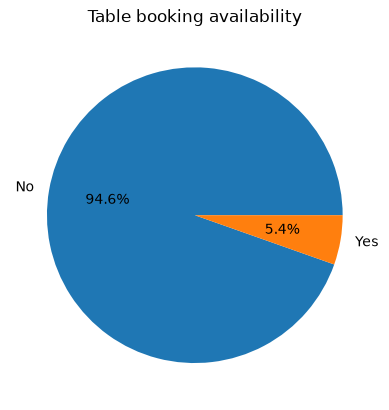

In [33]:
result.plot.pie(autopct="%1.1f%%")
plt.title("Table booking availability")
plt.show()

In [35]:
# Which five restaurants have the highest number of votes? 
Top5=df.nlargest(5,"VOTES")
Top5

,RESTAURANT NAME,ONLINE_ORDER,BOOK_TABLE,RATE,VOTES,APPROX_COST,LISTED_IN(TYPE)
38,Empire Restaurant,Yes,No,4.4,4884,750,other
86,Meghana Foods,Yes,No,4.4,4401,600,Dining
7,Onesta,Yes,Yes,4.6,2556,600,Cafes
44,Onesta,Yes,Yes,4.6,2556,600,other
65,Kabab Magic,Yes,No,4.1,1720,400,Dining


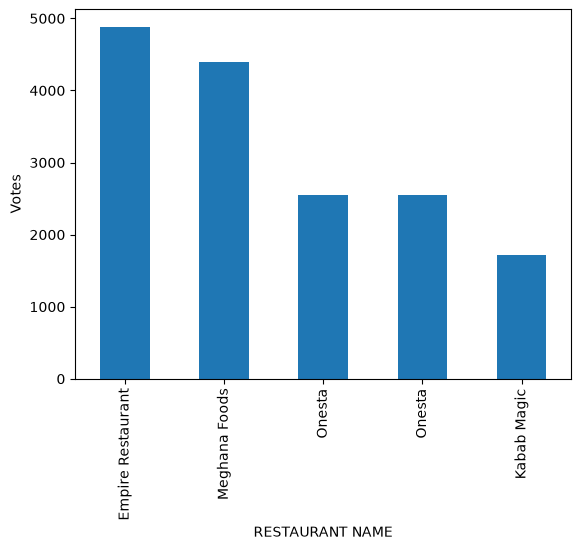

In [40]:
Top5.plot.bar(x="RESTAURANT NAME",y="VOTES",legend=False)
plt.ylabel("Votes")
plt.show()

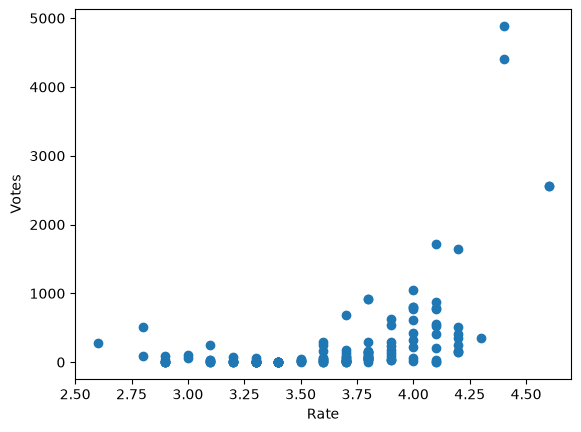

In [42]:
#Is there a relationship between restaurant ratings and customer votes? 
plt.scatter(df["RATE"],df["VOTES"])
plt.xlabel("Rate")
plt.ylabel("Votes")
plt.show()


In [46]:
# What is the average rating for each restaurant type? 
avg_rating=df.groupby("LISTED_IN(TYPE)")["RATE"].mean()
print(avg_rating.sort_values(ascending=False))

LISTED_IN(TYPE)
other     3.912500
Buffet    3.842857
Cafes     3.765217
Dining    3.571818
Name: RATE, dtype: float64


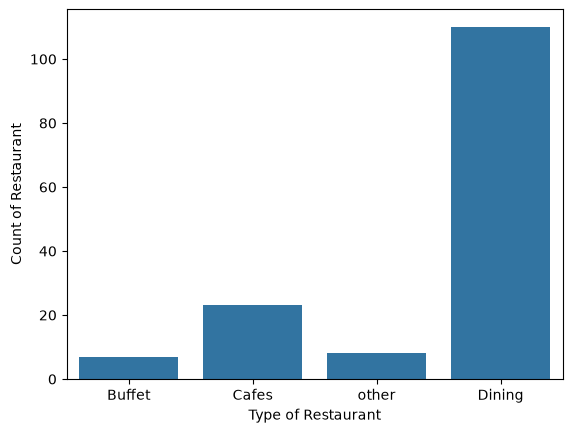

In [47]:
#Which restaurant type is most common in the dataset? 
sns.countplot(x=df["LISTED_IN(TYPE)"])
plt.xlabel("Type of Restaurant") 
plt.ylabel("Count of Restaurant")
plt.show()

Text(0, 0.5, 'Frequency')

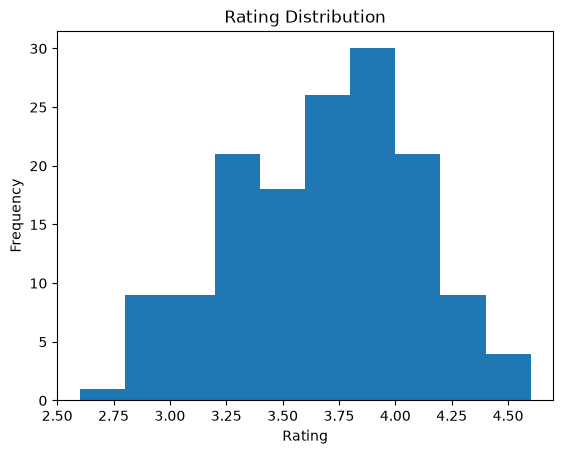

In [48]:
#What ratings do restaurants most commonly receive? 
plt.hist(df["RATE"],bins=10)
plt.title("Rating Distribution") 
plt.xlabel("Rating") 
plt.ylabel("Frequency")

In [49]:
#Which restaurant type has the highest average cost for two people? 
result=df.groupby("LISTED_IN(TYPE)")["APPROX_COST"].mean()
print(result.sort_values(ascending=False))

LISTED_IN(TYPE)
Buffet    671.428571
other     668.750000
Cafes     545.652174
Dining    357.272727
Name: APPROX_COST, dtype: float64


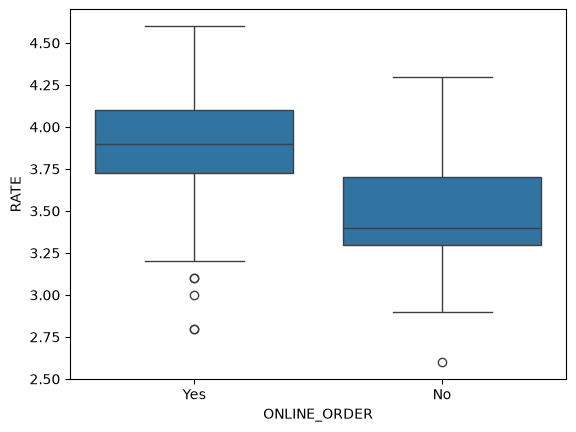

In [51]:
#Do restaurants offering online ordering have higher ratings?
sns.boxplot(data=df,x="ONLINE_ORDER",y="RATE")
plt.show()


In [52]:
#10. Which restaurant types have more records without online ordering? 
pivot_table=df.pivot_table(
    index="LISTED_IN(TYPE)",
    columns="ONLINE_ORDER",
    aggfunc="size",
    fill_value=0
)
pivot_table

ONLINE_ORDER,No,Yes
LISTED_IN(TYPE),,
Buffet,3,4
Cafes,8,15
Dining,77,33
other,2,6


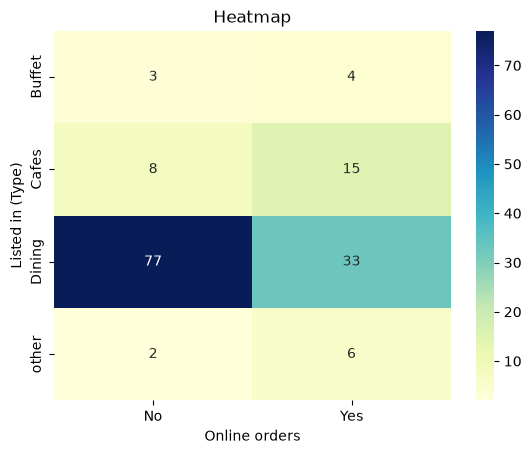

In [54]:
sns.heatmap(pivot_table,annot=True,cmap="YlGnBu",fmt="d")
plt.xlabel("Online orders")
plt.ylabel("Listed in (Type)")
plt.title("Heatmap")
plt.show()